# Problem
Recover tissue diffusion D, vascular signal fraction f, extra pseudodiffusion D*, and extrapolated S0 from real human spinal-cord diffusion MRI. We retain the entire author mask and all six slices. The standard method reference is independently executed original code, **not ground truth**. Numerical parity cannot establish blood velocity or absolute perfusion. This acquisition differs from tissue-only diffusion spectrum estimation by its vascular incoherent-motion unknowns.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.main import run
from src.solvers import reconstruct
from src.visualization import acquisition_figure,map_figure,spectral_figure,residual_figure,reference_figure,residual_values
from evaluation.judge import evaluate
image,mask,b,affine=load_data()
def unpack(path):
    with np.load(path) as z:return np.stack([z[k][0] for k in ['S0','diffusion','fraction','pseudodiffusion']],axis=-1)
original=unpack('notebooks/reference_outputs/upstream_one_step.npz')
original_two=unpack('notebooks/reference_outputs/upstream_two_step.npz')
print('Native shape',image.shape,'support',mask.sum(),'b',b,'affine',affine,sep='\n')

Native shape
(128, 134, 6, 11)
support
2523
b
[  5.  10.  20.  30.  50.  75. 150. 250. 600. 700. 800.]
affine
[[-7.82818794e-01  2.34916336e-10 -2.31670618e-01  5.52036171e+01]
 [ 4.06921841e-03  7.78137088e-01 -6.17235541e-01 -4.90873260e+01]
 [-3.43374275e-02  9.22145247e-02  5.20844078e+00  5.32312775e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


# Data
Measured 7 T right-left diffusion encoding, 11 b-values from5 to800 s/mm², native128×134×6 grid. Magnitude intensity is not normalized. Red contours mark the author dilated cord support; this includes low-SNR boundary voxels. There is no b=0 measurement or independent noise calibration. All2523 voxels contribute to evaluation. Spatially zoomed maps below retain all supported voxels; display zoom never changes computation.

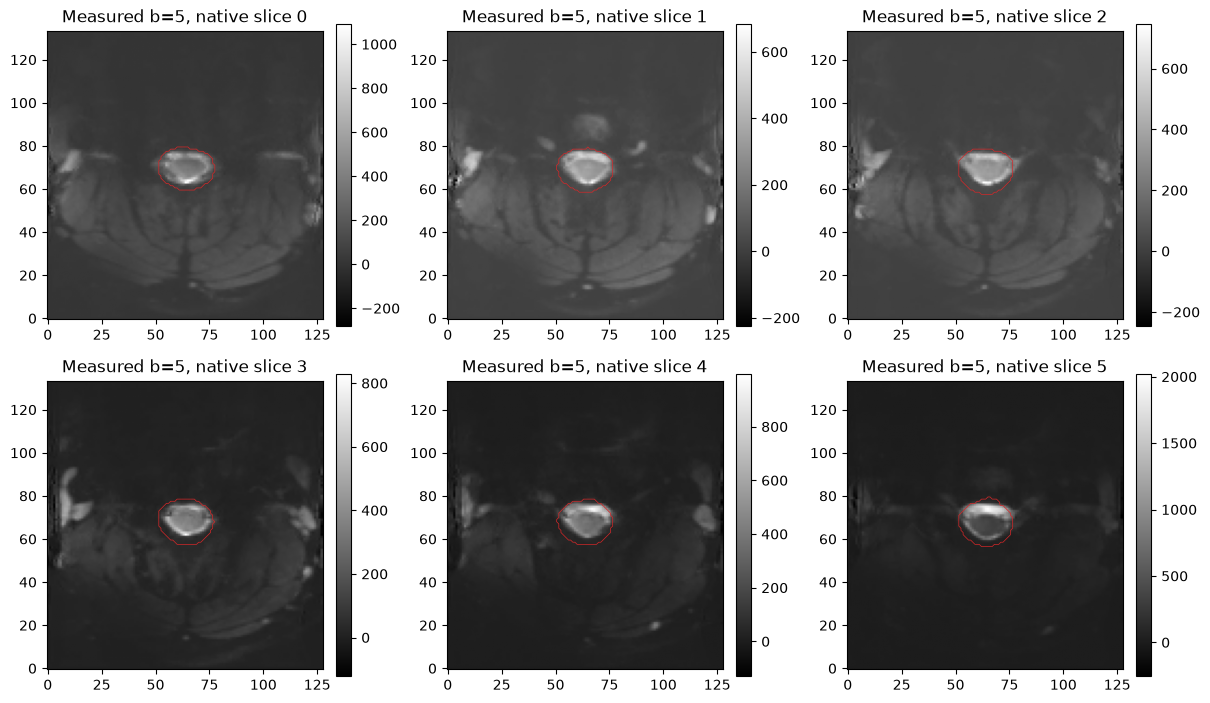

In [2]:
acquisition_figure(image,mask); plt.show()

# Physics
The forward signal is S(b)=S0 exp(-bD)[f exp(-bD*)+1-f]. D* is the **additional** coefficient, so the fast component decays with D+D*. D,D* have units mm²/s; f is a fraction. At f=0 changing D* has no effect. When D* approaches zero, vascular and tissue components coincide. This motivates fixed reference-f weights for D* error and reference[1-exp(-800D*)] weights for f error; fD* and complete observation reprojection are also evaluated. These are evaluation conventions, not target-derived public calibration.

# Method
The high-b log-linear initialization estimates D and S0(1-f), with bounded conjugate gradients. The primary one-step-v2 method jointly fits four parameters using differential evolution, then repeats within ±5% bounds. The segmented comparison fixes D at its high-b estimate throughout both population optimizations. All bounds, scalar sine parameter transforms, population updates, stopping criteria and residual order are implemented locally; NumPy/SciPy provide general computation only. The same original per-voxel seeds are used for reproducibility, not as hidden truth. Independent original alternate-seed measurements determined frozen evaluation margins before extraction.

In [3]:
start=time.perf_counter()
fresh=run()
primary_seconds=time.perf_counter()-start
start=time.perf_counter()
two=reconstruct(image,mask,b,method='two_step')
comparison_seconds=time.perf_counter()-start
# Computed monoexponential ablation: all measured high-b samples fit per voxel.
mono=np.zeros_like(fresh)
keep=b>=400
for loc_array in np.argwhere(mask):
    loc=tuple(loc_array);slope,intercept=np.polyfit(b[keep],np.log(image[loc][keep]),1)
    mono[loc]=[np.exp(intercept),max(0.,-slope),0.,0.]
report,code=evaluate('output/reconstruction.npz')
assert code==0,report
print('Full fresh runtimes',primary_seconds,comparison_seconds)
print(json.dumps(report,indent=2))

Full fresh runtimes 279.4061039000517 178.27838599996176
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "S0_rmse": 0.0,
    "D_rmse": 0.0,
    "fraction_weighted_rmse": 0.0,
    "Dstar_weighted_rmse": 0.0,
    "fDstar_rmse": 0.0,
    "observation_relative_l2": 0.3966103933830301
  },
  "thresholds": {
    "S0_rmse": {
      "comparison": "<=",
      "boundary": 0.6811477755077762
    },
    "D_rmse": {
      "comparison": "<=",
      "boundary": 1.666454616310215e-05
    },
    "fraction_weighted_rmse": {
      "comparison": "<=",
      "boundary": 0.01699014003074188
    },
    "Dstar_weighted_rmse": {
      "comparison": "<=",
      "boundary": 0.0032459965257982375
    },
    "fDstar_rmse": {
      "comparison": "<=",
      "boundary": 0.00022527093165768567
    },
    "observation_relative_l2": {
      "comparison": "<=",
      "boundary": 0.43627245704530293
    }
  },
  "errors": []
}


# Results
All four unknowns are shown for all six slices. Separate original/fresh comparisons establish implementation fidelity. The two-step and monoexponential alternatives are freshly computed, not substituted from archived results. Residuals use the same original intensity scale and every b-value. The weak vascular component and noise can drive boundary solutions; those voxels are retained and explicitly visible.

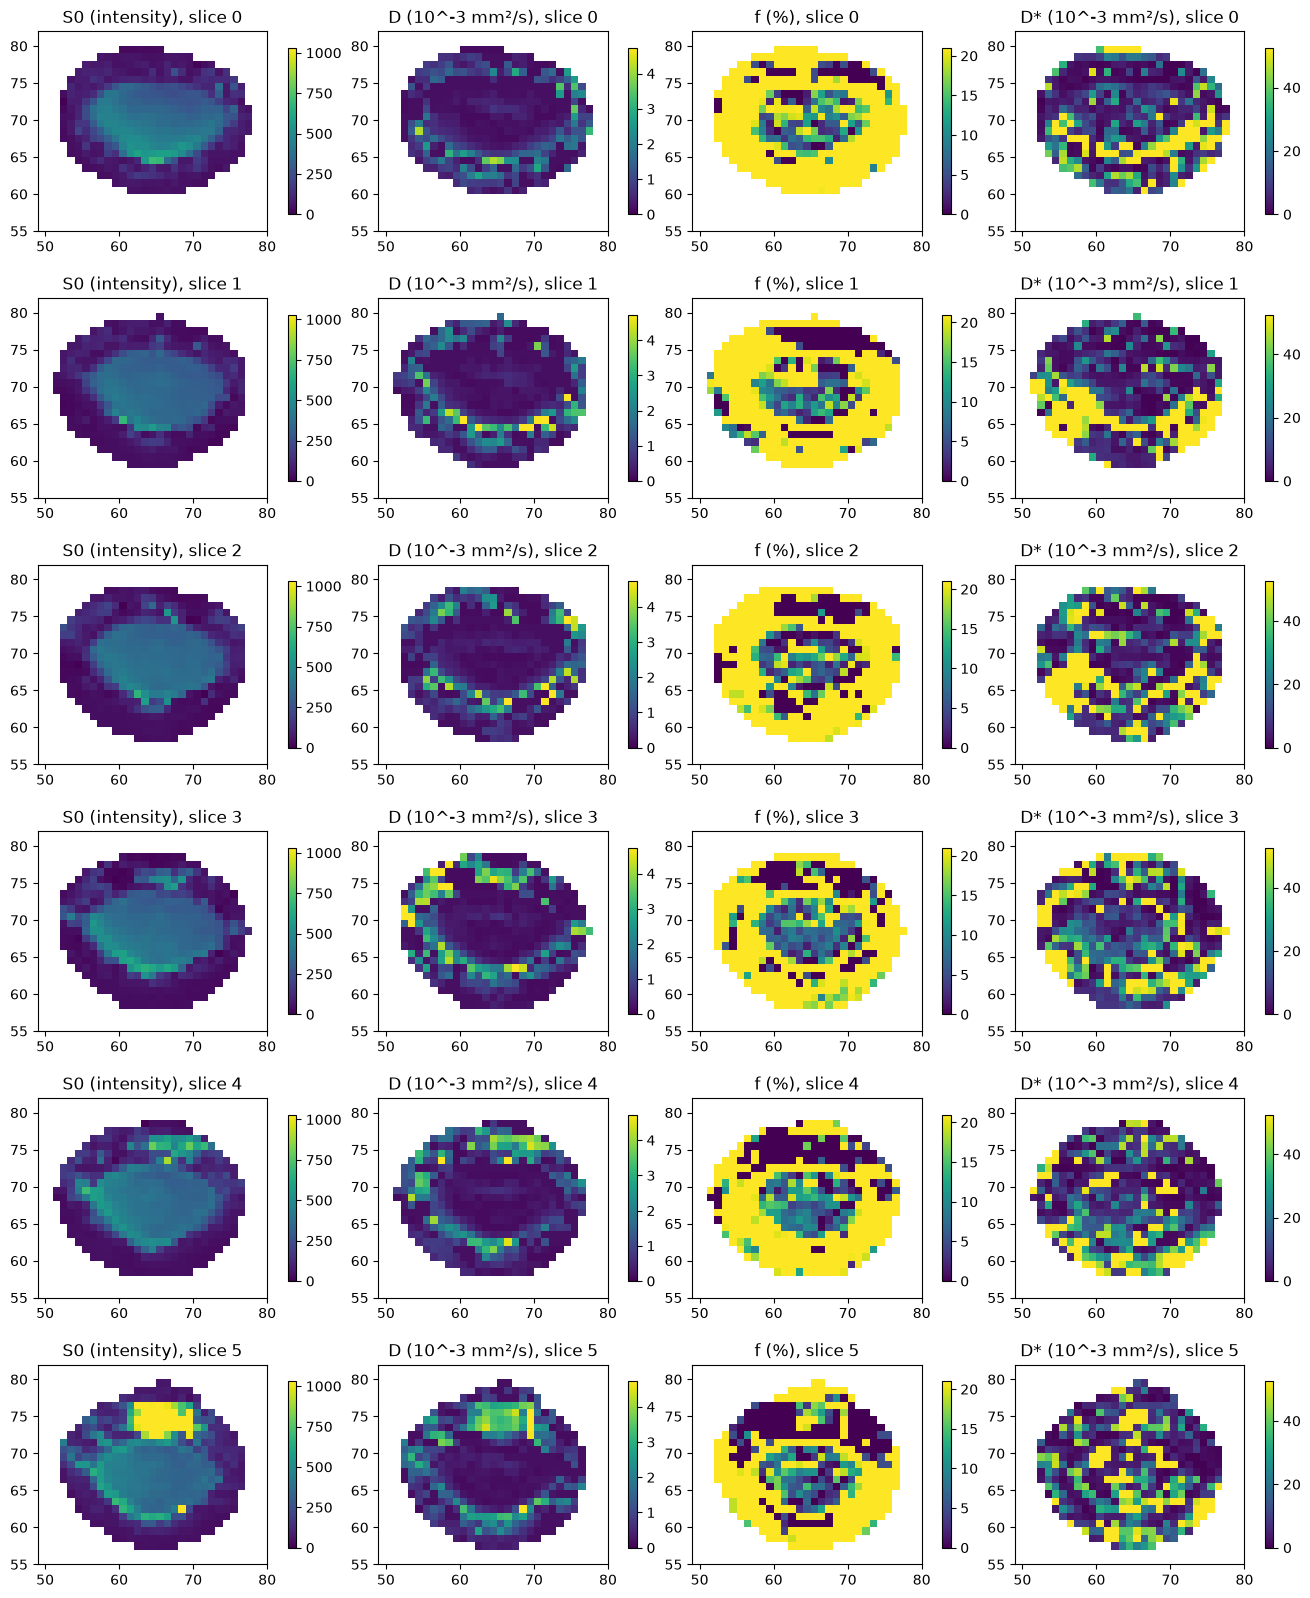

In [4]:
map_figure(fresh,mask); plt.show()

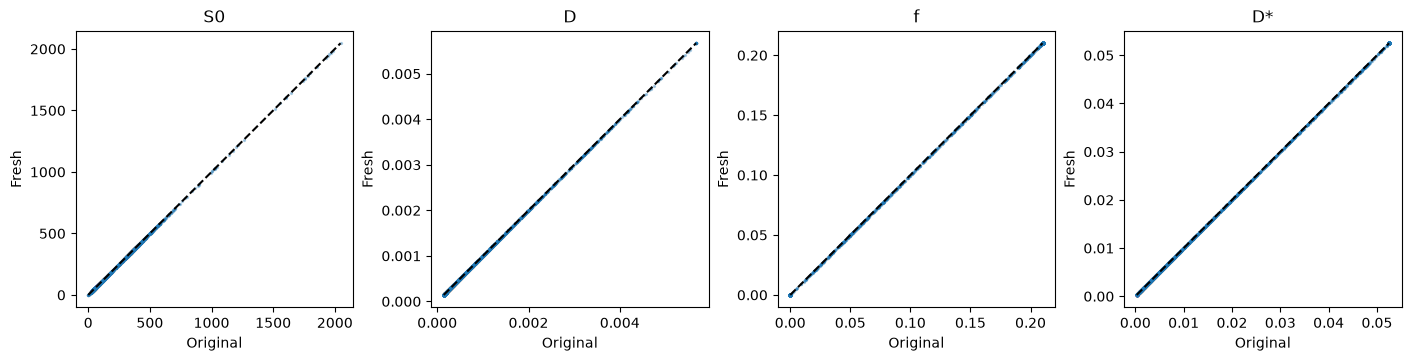

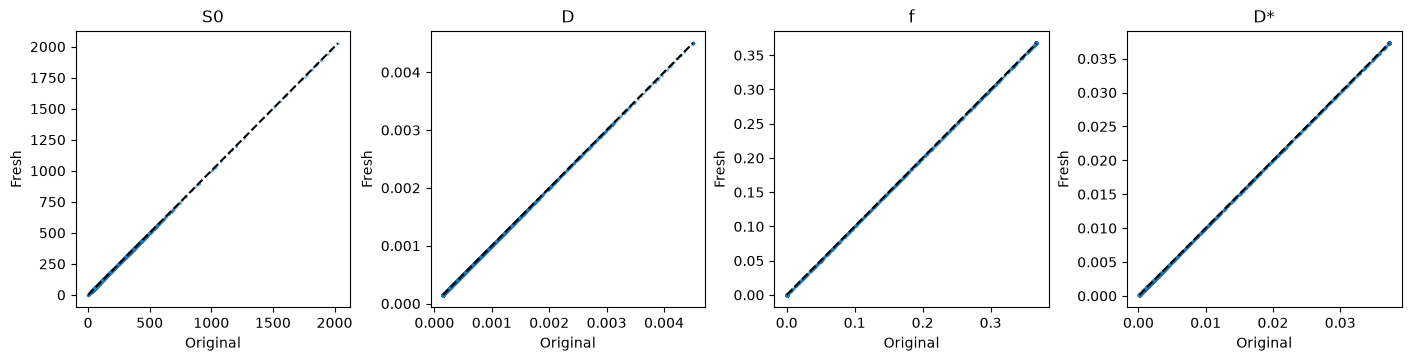

In [5]:
reference_figure(fresh,original,mask); plt.show()
reference_figure(two,original_two,mask); plt.show()

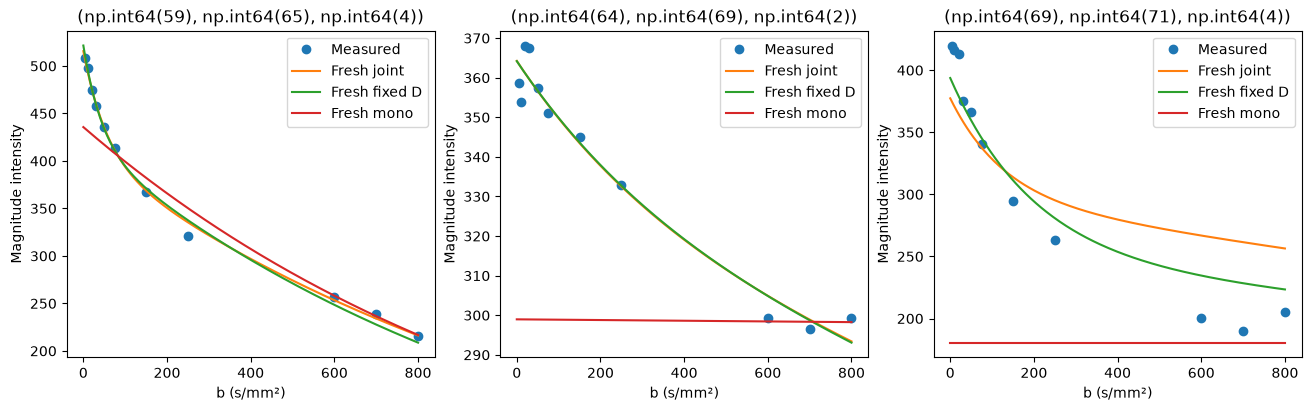

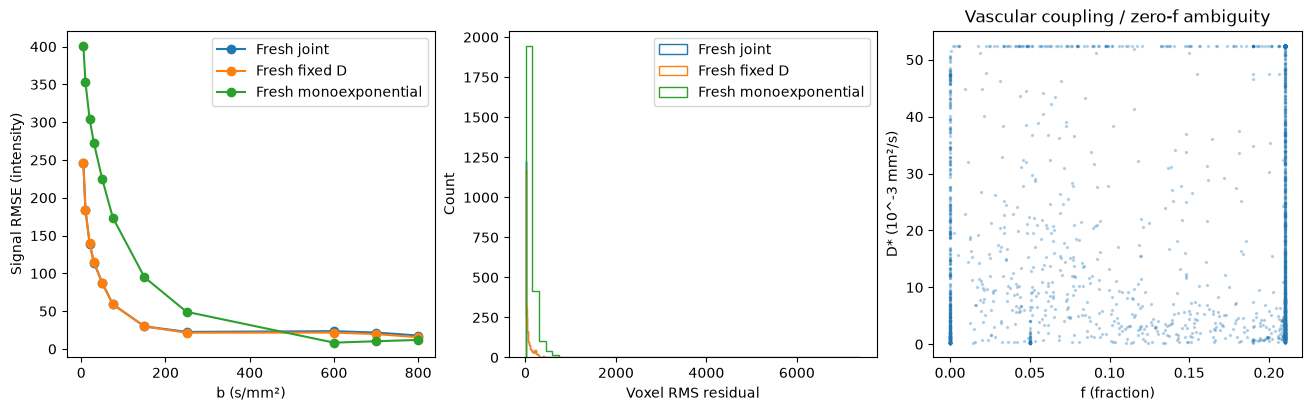

In [6]:
spectral_figure(image,mask,b,fresh,two,mono); plt.show()
residual_figure(image,mask,b,fresh,two,mono); plt.show()

[
  {
    "method": "Original joint",
    "signal_rmse": 113.18947082856413,
    "relative_l2": 0.3966103933830301,
    "near_zero_fraction": 0.17399920729290527
  },
  {
    "method": "Original fixed D",
    "signal_rmse": 113.05090618781163,
    "relative_l2": 0.39612486963002086,
    "near_zero_fraction": 0.1969877130400317
  },
  {
    "method": "Fresh joint",
    "signal_rmse": 113.18947082856413,
    "relative_l2": 0.3966103933830301,
    "near_zero_fraction": 0.17399920729290527
  },
  {
    "method": "Fresh fixed D",
    "signal_rmse": 113.05090618781163,
    "relative_l2": 0.39612486963002086,
    "near_zero_fraction": 0.1969877130400317
  },
  {
    "method": "Fresh mono",
    "signal_rmse": 222.46638122567788,
    "relative_l2": 0.7795113655584753,
    "near_zero_fraction": 1.0
  }
]


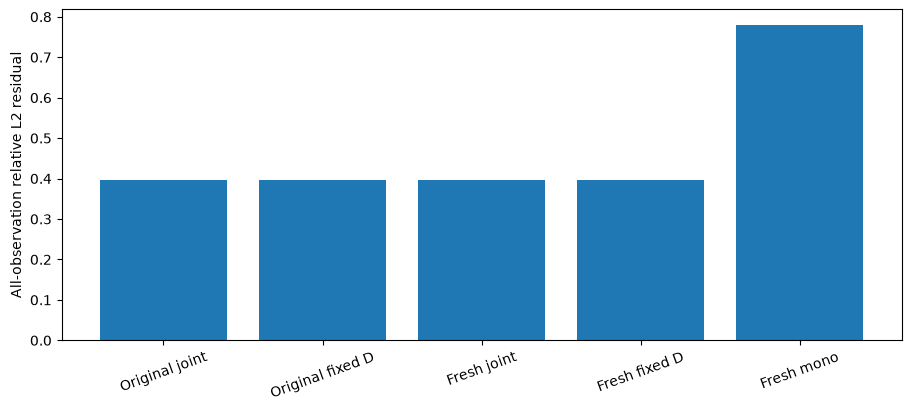

1919

In [7]:
rows=[]
for label,p in [('Original joint',original),('Original fixed D',original_two),('Fresh joint',fresh),('Fresh fixed D',two),('Fresh mono',mono)]:
    residual=residual_values(image,mask,b,p)
    rows.append({'method':label,'signal_rmse':float(np.sqrt(np.mean(residual**2))),'relative_l2':float(np.linalg.norm(residual)/np.linalg.norm(image[mask])),'near_zero_fraction':float(np.mean(p[...,2][mask]<1e-6))})
print(json.dumps(rows,indent=2))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.bar([r['method'] for r in rows],[r['relative_l2'] for r in rows]);ax.set_ylabel('All-observation relative L2 residual');ax.tick_params(axis='x',rotation=20);plt.show()
np.savez_compressed('notebooks/reference_outputs/fresh_comparisons.npz',one_step=fresh,two_step=two,mono=mono)
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps({'primary_seconds':primary_seconds,'comparison_seconds':comparison_seconds,'judge':report,'comparisons':rows},indent=2),encoding='utf-8')

# Conclusion
The full real acquisition is reconstructed and evaluated with all four declared outputs. Independent original agreement measures reproducibility; high residuals and zero-f regions limit biological interpretation. A fitted D* in a vanishing vascular component is not evidence of fast blood motion. Weighted coefficient metrics, vascular-strength product and all-observation residual jointly guard against reporting arbitrary maps as a successful inversion. The fixed-D and monoexponential comparisons isolate the effect of allowing tissue diffusion and vascular decay to vary.